# Caribu, 3: combine parameters

**What you will learn:** run the model on a grid of values of two parameters, gather the results in one table, and
find a classic law of canopy light in them: Beer's law.

**You need:** tutorial 2. **Run time:** about 10 seconds.

## 1. A grid: leaf area and leaf angle

The number of leaves sets the leaf area index (LAI), and the leaf inclination how much ground each leaf covers. Each
combination of 4 values of each is lit at noon under the overcast sky: 16 simulations. `variants` (from metafspm)
writes the 16 combinations, each a set of parameters named after its values.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.caribu.simulation import simulate
from openalea.metafspm.scene.scenarios import variants

combinations = variants({}, {"n_leaves": [2, 4, 6, 8], "leaf_inclination": [0., 30., 60., 80.]}, design="grid")
rows = []
for name, values in combinations.items():
    result = simulate(values, hours=1, start_hour=12)
    LAI = round(result.plants()["leaf_area"].sum() / result.ground_area, 2)
    rows.append({**values, "LAI": LAI, **result.summary.iloc[0][["absorbed_fraction", "soil_fraction"]]})
grid = pd.DataFrame(rows)
grid.pivot(index="LAI", columns="leaf_inclination", values="soil_fraction").round(3)

leaf_inclination,0.0,30.0,60.0,80.0
LAI,,,,
0.8,0.432,0.441,0.520,0.548
1.6,0.219,0.228,0.314,0.376
2.4,0.113,0.110,0.200,0.255
3.2,0.081,0.064,0.143,0.208


## 2. Beer's law

The share of light reaching the soil falls as the leaf area grows. Light crossing a canopy is attenuated much as
light crossing a cloudy liquid, by **Beer's law**:

$$\text{soil fraction} = e^{-k \cdot \text{LAI}}$$

The **extinction coefficient** $k$ says how much ground each unit of leaf area shades. It depends on the leaves'
angles, on how they are arranged, and on where the light comes from. On a logarithmic scale, Beer's law is a
straight line of slope −k:

leaf inclination (°)
0.0     0.85
30.0    0.89
60.0    0.65
80.0    0.54
Name: k, dtype: float64

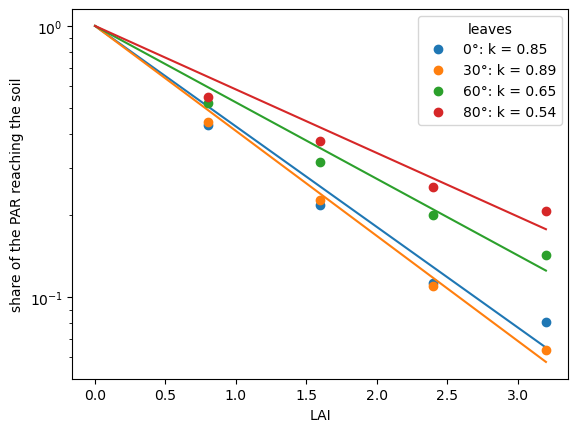

In [2]:
coefficients = {}
for inclination, rows_of_inclination in grid.groupby("leaf_inclination"):
    LAI, soil = rows_of_inclination["LAI"], rows_of_inclination["soil_fraction"]
    k = -np.sum(LAI * np.log(soil)) / np.sum(LAI ** 2)          # the least squares slope through the origin
    coefficients[inclination] = k
    line = plt.plot(LAI, soil, "o", label=f"{inclination:.0f}°: k = {k:.2f}")[0]
    plt.plot(np.linspace(0, LAI.max(), 50), np.exp(-k * np.linspace(0, LAI.max(), 50)), color=line.get_color())
plt.yscale("log"); plt.xlabel("LAI"); plt.ylabel("share of the PAR reaching the soil"); plt.legend(title="leaves")
pd.Series(coefficients, name="k").rename_axis("leaf inclination (°)").round(2)

**Reading the figure.** For each inclination the points lie close to a line: Beer's law is a good approximation
here. From 30° up, $k$ falls as the leaves get more upright: at 80° a unit of leaf area shades much less ground than
at 30°.

Flat leaves (0°) are an exception: with many leaves, they shade less than leaves at 30°. The plants' leaves leave
the stem on alternate sides, so with 4 or more leaves, several leaves lie on the same side, one above the other. Flat,
they lie exactly above each other: the upper ones shade the lower ones instead of the ground. (With a single leaf
per plant, flat leaves do shade the most: try it below.) This effect of the leaves' arrangement, called
**clumping**, is one reason why real canopies depart from Beer's law.

The two parameters **combine**: the effect of adding leaves depends on their angle.

Beer's law is how experimenters estimate the LAI of a field from light measured below it (tutorial 5 uses this
idea). A model such as Caribu computes the light leaf by leaf, without assuming the law, and can be checked against
it.

## Try it yourself

1. Light stands of plants with a single leaf (`{"n_leaves": 1}`) at 0° and 30°: which leaves shade the soil most?
   Repeat the grid with the sun at 10 h (`{"sun": True}`, `start_hour=10`): does $k$ change?
2. Replace the number of leaves by the plant spacing (`plant_spacing=` 0.03, 0.05, 0.08): is the law the same?
3. Add the absorbed share to the analysis. Is `1 - absorbed_fraction` also exponential?

**Next:** `04_sensitivity_analysis.ipynb`.